# Ejercicio k-Nearest Neighbor

## App Reviews
En este ejercicio vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating, en función del sentimiento del comentario y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

## Importamos las librerías que vamos a utilizar

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Leemos nuestro archivo de entrada `reviews_sentiment`

Para facilitar el ejercicio, las columnas que utilizaremos serán: wordcount con la cantidad de palabras utilizadas y sentimentValue con un valor entre -4 y 4 que indica si el comentario fue valorado como positivo o negativo

Nuestras etiquetas, serán las estrellas que dieron los usuarios a la app, que son valores discretos del 1 al 5

In [4]:
df = pd.read_csv('data/reviews_sentiment.csv', header=0, sep=';')

In [5]:
df

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,Hola desde hace algo más de un mes me pone sin...,23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas...,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784
...,...,...,...,...,...,...,...
252,Muy buena aplicacion,Muy buena genial,3,positive,positive,5,2.814818
253,Buena,Genial,1,positive,positive,5,2.924393
254,Wuau,Genial,1,positive,positive,5,2.924393
255,Muy buena,Genial,1,positive,positive,5,2.924393


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    object 
 1   Review Text     257 non-null    object 
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    object 
 4   textSentiment   257 non-null    object 
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 14.2+ KB


In [7]:
df.describe()

,wordcount,Star Rating,sentimentValue
count,257.000000,257.000000,257.000000
mean,11.501946,3.420233,0.383849
std,13.159812,1.409531,0.897987
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.108144
50%,7.000000,3.000000,0.264091
75%,16.000000,5.000000,0.808384
max,103.000000,5.000000,3.264579


## Rápidas visualizaciones y análisis
Al menos realiza un análisis univariante y representa la distribución del rating. Realiza otras visualizaciones para ver la relación de tus datos.

In [8]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

wordcount


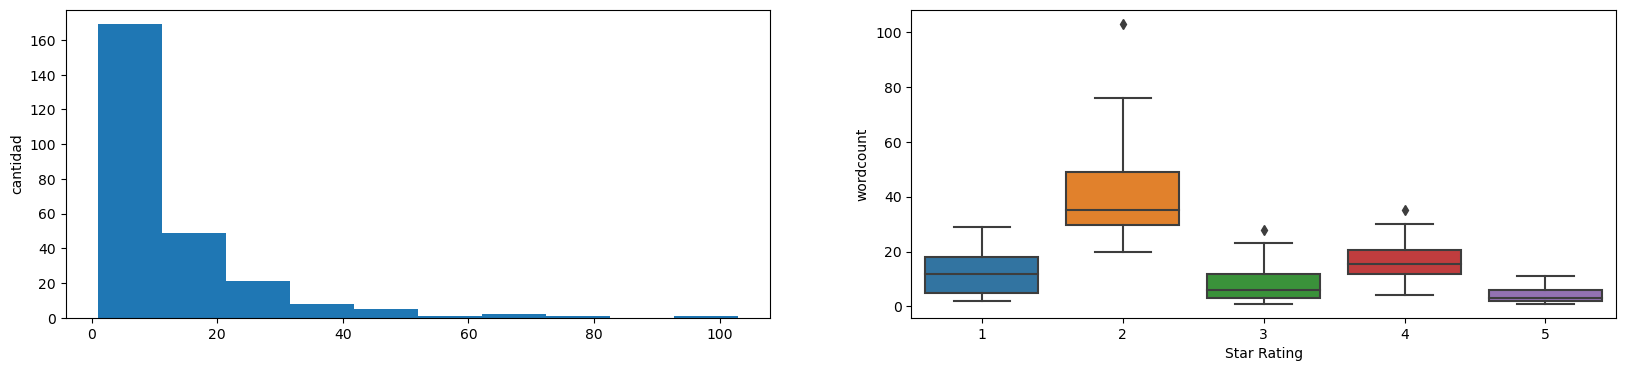

Star Rating


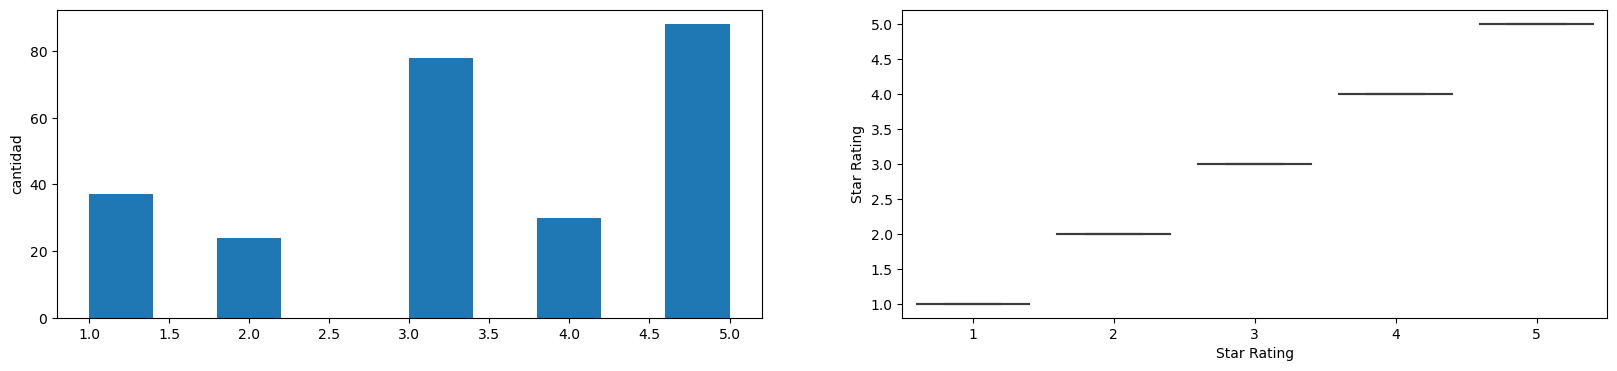

sentimentValue


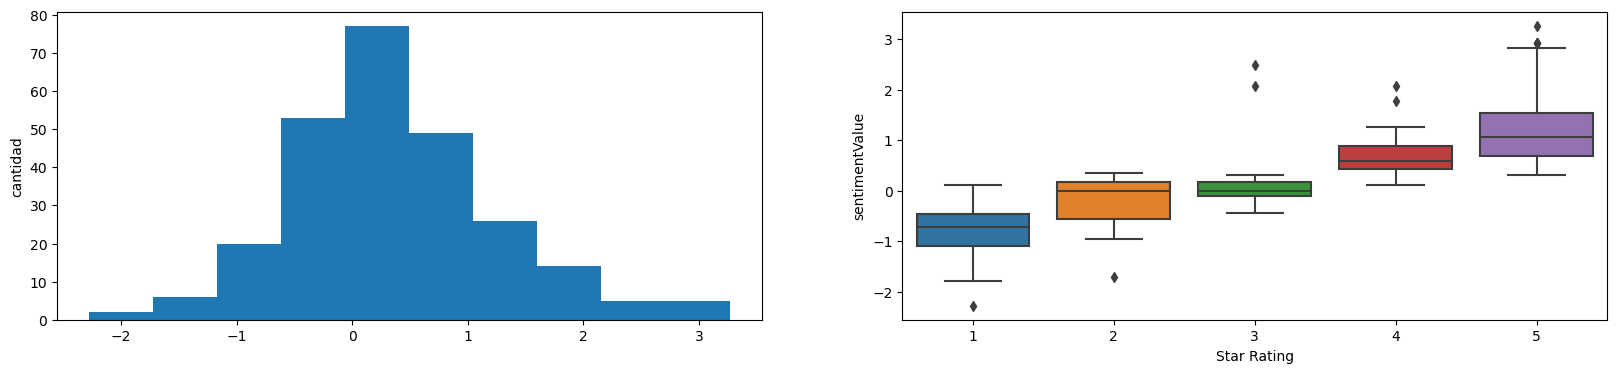

In [11]:
for col in num_cols:
    print(col)
    plt.figure(figsize = (20, 4))
    plt.subplot(1, 2, 1)
    plt.hist(df[col])
    plt.ylabel('cantidad')
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df['Star Rating'], y=df[col])
    plt.show()

In [20]:
m_corr = df.corr(method='spearman', numeric_only=True)

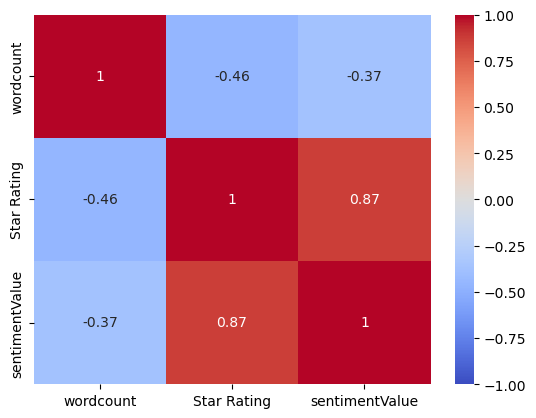

In [21]:
sns.heatmap(m_corr, vmin=-1, annot=True, cmap='coolwarm');

## Preparamos el dataset
Divide en train/test y escala las features en el rango [0, 1].

In [22]:
X = df[['wordcount', 'sentimentValue']]
y = df['Star Rating']

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scal = scaler.fit_transform(X_train)
X_test_scal = scaler.transform(X_test)

## Creamos el Modelo
Entrena con un KNN y evalúa el error en train y en test

In [26]:
from sklearn.neighbors import KNeighborsClassifier

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [28]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scal, y_train)

y_pred_train = knn.predict(X_train_scal)
y_pred_test = knn.predict(X_test_scal)

## Evalúa tu modelo

In [36]:
print("Accuracy-train:", accuracy_score(y_train, y_pred_train))
# print("Precision-train:", precision_score(y_train, y_pred_train, average=None))
# print("Recall-train:", recall_score(y_train, y_pred_train, average=None))
# print("F1 score-train:", f1_score(y_train, y_pred_train, average=None))
print("\nClassification Report - train:\n", classification_report(y_train, y_pred_train))
print("Accuracy-test:", accuracy_score(y_test, y_pred_test))
# print("Precision-test:", precision_score(y_test, y_pred_test, average=None))
# print("Recall-test:", recall_score(y_test, y_pred_test, average=None))
# print("F1 score-test:", f1_score(y_test, y_pred_test, average=None))
print("\nClassification Report - test:\n", classification_report(y_test, y_pred_test))

Accuracy-train: 0.9170731707317074

Classification Report - train:
               precision    recall  f1-score   support

           1       0.93      0.96      0.95        27
           2       0.95      0.86      0.90        22
           3       0.88      0.94      0.91        64
           4       0.94      0.70      0.80        23
           5       0.93      0.97      0.95        69

    accuracy                           0.92       205
   macro avg       0.93      0.89      0.90       205
weighted avg       0.92      0.92      0.92       205

Accuracy-test: 0.8269230769230769

Classification Report - test:
               precision    recall  f1-score   support

           1       0.82      0.90      0.86        10
           2       0.40      1.00      0.57         2
           3       0.85      0.79      0.81        14
           4       1.00      0.43      0.60         7
           5       0.90      0.95      0.92        19

    accuracy                           0.83        

## ¿Cómo obtener el mejor valor de k? Crea y evalúa nuevos modelos
¿Qué valor de k maximiza el accuracy? Representa todas las iteraciones en un scatterplot -> k vs accuracy

In [41]:
acc_train = []
acc_test = []

for k in range(1, 30):
    knnk = KNeighborsClassifier(n_neighbors=k)
    knnk.fit(X_train_scal, y_train)
    print('K=', k)
    y_pred_train_k = knnk.predict(X_train_scal)
    y_pred_test_k = knnk.predict(X_test_scal)
    acc_train_k = accuracy_score(y_train, y_pred_train_k)
    acc_test_k = accuracy_score(y_test, y_pred_test_k)
    acc_train.append(acc_train_k)
    acc_test.append(acc_test_k)
    print("Accuracy-train:", acc_train_k)
    print("Accuracy-test:", acc_test_k)
    print('-'*50)

K= 1
Accuracy-train: 0.9902439024390244
Accuracy-test: 0.8269230769230769
--------------------------------------------------
K= 2
Accuracy-train: 0.926829268292683
Accuracy-test: 0.8461538461538461
--------------------------------------------------
K= 3
Accuracy-train: 0.9414634146341463
Accuracy-test: 0.8269230769230769
--------------------------------------------------
K= 4
Accuracy-train: 0.926829268292683
Accuracy-test: 0.8076923076923077
--------------------------------------------------
K= 5
Accuracy-train: 0.9170731707317074
Accuracy-test: 0.8269230769230769
--------------------------------------------------
K= 6
Accuracy-train: 0.926829268292683
Accuracy-test: 0.8076923076923077
--------------------------------------------------
K= 7
Accuracy-train: 0.9073170731707317
Accuracy-test: 0.8269230769230769
--------------------------------------------------
K= 8
Accuracy-train: 0.9121951219512195
Accuracy-test: 0.8076923076923077
--------------------------------------------------
K= 

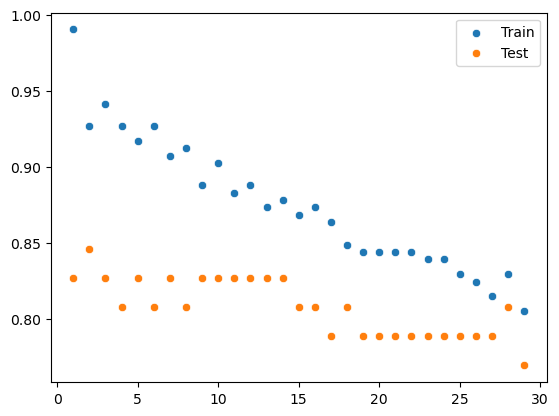

In [54]:
sns.scatterplot(x=range(1,30), y=acc_train);
sns.scatterplot(x=range(1,30), y=acc_test);
plt.legend(['Train', 'Test']);

In [58]:
s_acc_test = pd.Series(acc_test)
s_acc_test.sort_values(ascending=False)

1     0.846154
0     0.826923
2     0.826923
4     0.826923
6     0.826923
8     0.826923
9     0.826923
10    0.826923
11    0.826923
12    0.826923
13    0.826923
27    0.807692
17    0.807692
15    0.807692
14    0.807692
7     0.807692
5     0.807692
3     0.807692
16    0.788462
18    0.788462
19    0.788462
20    0.788462
21    0.788462
22    0.788462
23    0.788462
24    0.788462
25    0.788462
26    0.788462
28    0.769231
dtype: float64

La accuracy en test se maximiza con k = 2. 

## Predice con nuevos datos.
Ejemplo: supongamos que nos llega una review de 5 palabras y sentimiento 1

In [62]:
X.columns

Index(['wordcount', 'sentimentValue'], dtype='object')

In [65]:
X_new = pd.DataFrame({'wordcount': [5], 'sentimentValue': [1]})
X_new_scal = scaler.transform(X_new)

knn_opt = KNeighborsClassifier(n_neighbors=2)

knn_opt.fit(X_train_scal, y_train)

y_pred_new = knn_opt.predict(X_new_scal)
y_pred_new

array([5], dtype=int64)